# Experiment 7: Support Vector Machine with Linear and Non-linear Kernels
**Aim:** Train SVM classifiers with linear, RBF and polynomial kernels and compare their performance.

**Datasets:**
- Part A: Breast Cancer Wisconsin (built into scikit-learn), 569 samples, 30 features
- Part B: Moons (generated with scikit-learn), 2D data that is **not linearly separable**, used to visualise the decision boundaries

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.inspection import DecisionBoundaryDisplay
import warnings
warnings.filterwarnings("ignore")

## Part A: Compare kernels on Breast Cancer data

In [3]:
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()                 # SVM is distance-based, so scaling is a must
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
results = []
for kernel in ["linear", "rbf", "poly"]:
    model = SVC(kernel=kernel)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append([kernel,
                    accuracy_score(y_test, y_pred),
                    precision_score(y_test, y_pred),
                    recall_score(y_test, y_pred),
                    f1_score(y_test, y_pred),
                    roc_auc_score(y_test, model.decision_function(X_test)),
                    model.n_support_.sum()])

results = pd.DataFrame(results, columns=["Kernel", "Accuracy", "Precision", "Recall",
                                         "F1-score", "ROC-AUC", "Support Vectors"]).round(4)
results

,Kernel,Accuracy,Precision,Recall,F1-score,ROC-AUC,Support Vectors
0,linear,0.9737,0.9859,0.9722,0.9790,0.9964,32
1,rbf,0.9825,0.9861,0.9861,0.9861,0.9950,97
2,poly,0.9123,0.8780,1.0000,0.9351,0.9954,145


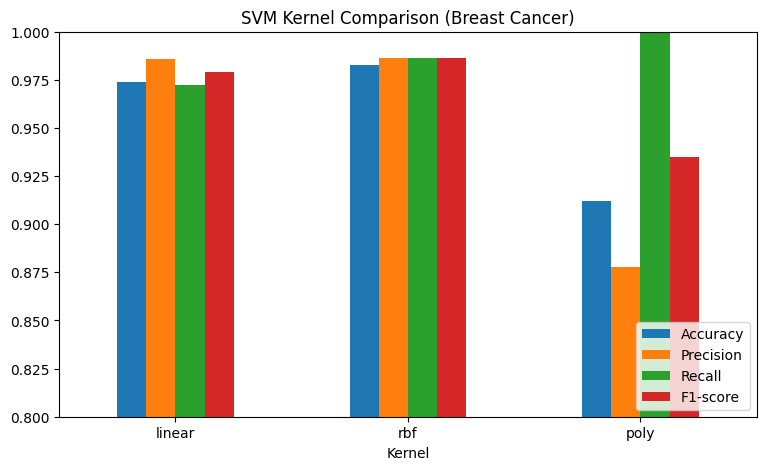

In [5]:
results.set_index("Kernel")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", ylim=(0.8, 1.0), rot=0, figsize=(9, 5))
plt.title("SVM Kernel Comparison (Breast Cancer)")
plt.legend(loc="lower right")
plt.show()

## Part B: See the decision boundaries on non-linear (moons) data

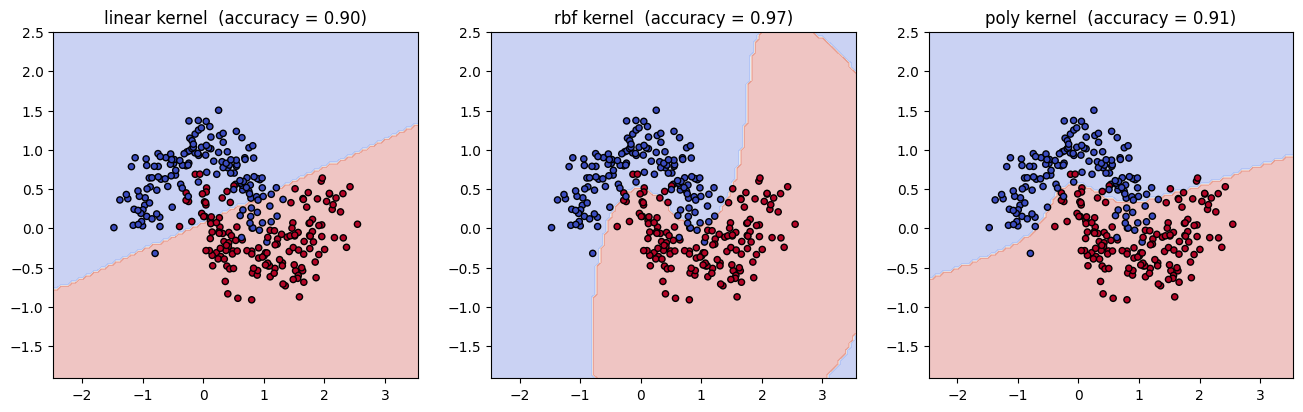

In [6]:
X2, y2 = make_moons(n_samples=300, noise=0.2, random_state=42)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.3, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, kernel in zip(axes, ["linear", "rbf", "poly"]):
    model = SVC(kernel=kernel)
    model.fit(X2_train, y2_train)
    acc = accuracy_score(y2_test, model.predict(X2_test))
    DecisionBoundaryDisplay.from_estimator(model, X2, response_method="predict",
                                           cmap="coolwarm", alpha=0.3, ax=ax)
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", edgecolors="k", s=20)
    ax.set_title(f"{kernel} kernel  (accuracy = {acc:.2f})")
plt.show()

## Conclusion
- On Breast Cancer, **RBF** is best (≈98% accuracy), linear is close (≈97%) because this data is almost linearly separable, and poly is weakest (≈91%).
- On Moons, the **linear kernel can only draw a straight line** (≈90%), while the **RBF kernel bends around the curved shape** (≈97%).
- Non-linear kernels (RBF) map the data to a higher dimension (the kernel trick), so SVM can separate classes that a straight line cannot.